# 🔄 Phase 3: Setup Validation Cross-Project (Leave-One-Project-Out / LOOCV)

**Penelitian**: *Predicting Flaky Test in Cross-Project Scenario*

> **[!IMPORTANT]**
> **Jangan gunakan Random Train-Test Split biasa!** Random split akan mencampur test dari proyek yang sama ke dalam train set dan test set, menyebabkan *data leakage* dan evaluasi yang bias/overoptimis.

Notebook ini merealisasikan **Phase 3**:
1. **Skema Utama: Leave-One-Project-Out Cross-Validation (LOOCV / LOPO-CV)**:
   - Terdapat 24 proyek unik.
   - Untuk tiap fold $i \in \{1, \dots, 24\}$:
     - **Test Set**: Data test cases dari proyek $P_i$.
     - **Train Set**: Data test cases dari 23 proyek lainnya ($P_{j \neq i}$).
2. **Skenario Tambahan: Multi-Project Split (70% Train Proyek, 30% Test Proyek)**:
   - Stratified/balanced split pada level *project* (misal: 17 proyek Train, 7 proyek Test).
3. **Modular Split Generator & Verifikasi Data Leakage**:
   - Memvalidasi bahwa tidak ada irisan `project` maupun `test_name` antara Train dan Test set.
   - Inspeksi distribusi ukuran sampel dan rasio kelas target (`flaky`) di setiap fold.
4. **Export Index / Metadata Split Fold**: Menyimpan konfigurasi split agar *reproducible* untuk Phase 4 (Model Training).

## 1. Import Library & Load Engineered Dataset

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import LeaveOneGroupOut

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)

data_path = "../data/engineered_test_features.csv"
df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"Total Unique Projects: {df['project'].nunique()}")
df[['project', 'test_name', 'flaky']].head(3)

Dataset Shape: 22236 baris, 58 kolom
Total Unique Projects: 24


,project,test_name,flaky
0,logback,ch.qos.logback.classic.asyncappendertest.event...,0
1,logback,ch.qos.logback.classic.asyncappendertest.setti...,0
2,logback,ch.qos.logback.classic.boolex.geventevaluatort...,0


## 2. Definisi Matriks Fitur ($X$), Label Target ($y$), dan Group Identitas (`project`)

Untuk memastikan model bersifat **project-agnostic**, seluruh identifier proyek (`project`, `test_name`, `Unnamed: 0`, `testClassName`, `testMethodName`) dipisahkan dari $X$.

In [2]:
# Metadata & target
meta_cols = ['Unnamed: 0', 'test_name', 'project', 'testClassName', 'testMethodName']
target_col = 'flaky'

# Identifikasi feature columns (tersedia feature raw, engineered ratios, log, robust/standard scaled, dan PCA)
feature_cols = [c for c in df.columns if c not in meta_cols + [target_col]]

print(f"Total Fitur Tersedia: {len(feature_cols)}")
print("Sample Fitur:", feature_cols[:10])

X = df[feature_cols]
y = df[target_col]
groups = df['project']

Total Fitur Tersedia: 52
Sample Fitur: ['assertion-roulette', 'conditional-test-logic', 'eager-test', 'fire-and-forget', 'indirect-testing', 'mystery-guest', 'resource-optimism', 'test-run-war', 'testLength', 'numAsserts']


## 3. Implementasi Leave-One-Project-Out Cross-Validation (LOOCV / LOPO)

Kita membuat generator LOOCV menggunakan `LeaveOneGroupOut` dari scikit-learn atau iterasi list proyek, dan memverifikasi integritas setiap fold.

In [3]:
logo = LeaveOneGroupOut()
fold_stats = []

loocv_splits = {}

for fold_idx, (train_idx, test_idx) in enumerate(logo.split(X, y, groups=groups), 1):
    test_project = df.iloc[test_idx]['project'].unique()[0]
    train_projects = df.iloc[train_idx]['project'].unique().tolist()
    
    # Leakage check: memastikan test_project sama sekali tidak ada di train_projects
    assert test_project not in train_projects, f"Data leakage terdeteksi pada fold {fold_idx}!"
    
    n_train = len(train_idx)
    n_test = len(test_idx)
    flaky_train = int(y.iloc[train_idx].sum())
    flaky_test = int(y.iloc[test_idx].sum())
    flaky_test_pct = (flaky_test / n_test) * 100 if n_test > 0 else 0
    
    fold_stats.append({
        'Fold': fold_idx,
        'Test Project': test_project,
        'Train Size': n_train,
        'Test Size': n_test,
        'Flaky in Train': flaky_train,
        'Flaky in Test': flaky_test,
        'Test Flaky (%)': round(flaky_test_pct, 2)
    })
    
    loocv_splits[test_project] = {
        'fold': fold_idx,
        'train_indices': train_idx.tolist(),
        'test_indices': test_idx.tolist()
    }

df_fold_stats = pd.DataFrame(fold_stats)
print("=== Ringkasan 24 Fold LOOCV ===")
df_fold_stats

=== Ringkasan 24 Fold LOOCV ===


,Fold,Test Project,Train Size,Test Size,Flaky in Train,Flaky in Test,Test Flaky (%)
0,1,achilles,20919,1317,807,4,0.30
1,2,activiti,20192,2044,779,32,1.57
2,3,alluxio,22049,187,695,116,62.03
3,4,ambari,21912,324,759,52,16.05
4,5,assertj-core,15975,6261,810,1,0.02
5,6,commons-exec,22181,55,810,1,1.82
6,7,elastic-job-lite,21678,558,808,3,0.54
7,8,handlebars.java,21809,427,810,1,0.23
8,9,hbase,21805,431,666,145,33.64
9,10,hector,22094,142,778,33,23.24


### 3.1 Visualisasi Distribusi Test Sample & Rasio Flaky per Fold LOOCV

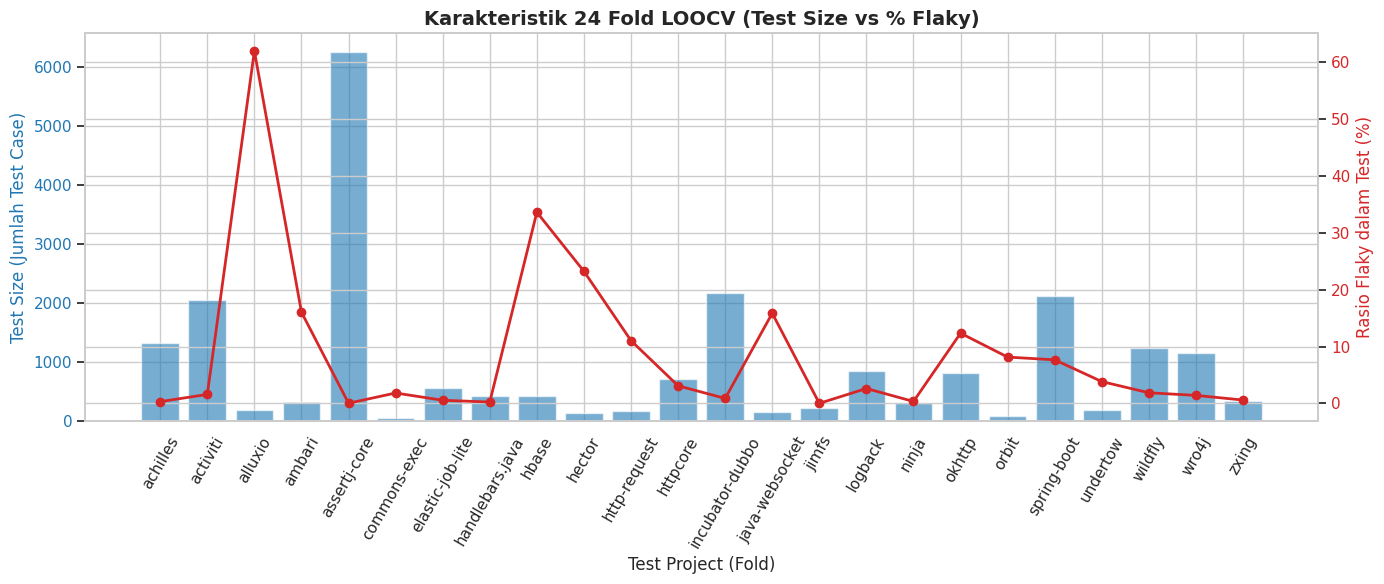

In [4]:
fig, ax1 = plt.subplots(figsize=(14, 6))

color = 'tab:blue'
ax1.set_xlabel('Test Project (Fold)', fontsize=12)
ax1.set_ylabel('Test Size (Jumlah Test Case)', color=color, fontsize=12)
bars = ax1.bar(df_fold_stats['Test Project'], df_fold_stats['Test Size'], color=color, alpha=0.6, label='Test Size')
ax1.tick_params(axis='y', labelcolor=color)
ax1.tick_params(axis='x', rotation=60)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Rasio Flaky dalam Test (%)', color=color, fontsize=12)
line = ax2.plot(df_fold_stats['Test Project'], df_fold_stats['Test Flaky (%)'], color=color, marker='o', linewidth=2, label='Flaky %')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Karakteristik 24 Fold LOOCV (Test Size vs % Flaky)', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

## 4. Skenario Tambahan: Multi-Project Split (70% Train Projects, 30% Test Projects)

Selain LOOCV (1 vs 23), skenario multi-project split menguji ketahanan model saat dilatih pada kumpulan 70% proyek (~17 proyek) dan dievaluasi sekaligus pada sekumpulan 30% proyek (~7 proyek).

In [5]:
np.random.seed(42)
unique_projects = np.array(sorted(df['project'].unique()))
n_total_projects = len(unique_projects)
n_train_projects = int(np.round(0.7 * n_total_projects)) # 17 proyek

# Acak urutan project untuk split 70/30
shuffled_projects = np.random.permutation(unique_projects)
train_proj_set = sorted(shuffled_projects[:n_train_projects].tolist())
test_proj_set = sorted(shuffled_projects[n_train_projects:].tolist())

train_multi_idx = df[df['project'].isin(train_proj_set)].index.tolist()
test_multi_idx = df[df['project'].isin(test_proj_set)].index.tolist()

print("=== Multi-Project Split (70/30) ===")
print(f"Train Projects ({len(train_proj_set)}): {train_proj_set}")
print(f"Test Projects  ({len(test_proj_set)}): {test_proj_set}")
print(f"Train Samples : {len(train_multi_idx)} (Flaky: {y.iloc[train_multi_idx].sum()}, {y.iloc[train_multi_idx].mean()*100:.2f}%)")
print(f"Test Samples  : {len(test_multi_idx)} (Flaky: {y.iloc[test_multi_idx].sum()}, {y.iloc[test_multi_idx].mean()*100:.2f}%)")

# Verifikasi tidak ada overlap proyek
assert len(set(train_proj_set).intersection(set(test_proj_set))) == 0, "Overlap proyek terdeteksi!"

=== Multi-Project Split (70/30) ===
Train Projects (17): ['achilles', 'activiti', 'alluxio', 'ambari', 'assertj-core', 'commons-exec', 'hbase', 'hector', 'httpcore', 'incubator-dubbo', 'java-websocket', 'logback', 'ninja', 'okhttp', 'orbit', 'wildfly', 'wro4j']
Test Projects  (7): ['elastic-job-lite', 'handlebars.java', 'http-request', 'jimfs', 'spring-boot', 'undertow', 'zxing']
Train Samples : 18221 (Flaky: 617, 3.39%)
Test Samples  : 4015 (Flaky: 194, 4.83%)


## 5. Simpan Konfigurasi & Metadata Validasi Split

Menyimpan konfigurasi fold ke file JSON/CSV agar dapat dibaca langsung oleh pipeline pelatihan model pada Phase 4.

In [6]:
split_config = {
    'strategy_primary': 'Leave-One-Project-Out (LOOCV)',
    'num_folds': len(loocv_splits),
    'loocv_folds': {
        proj: {
            'fold': info['fold'],
            'test_project': proj,
            'train_size': len(info['train_indices']),
            'test_size': len(info['test_indices'])
        }
        for proj, info in loocv_splits.items()
    },
    'multi_project_split_70_30': {
        'train_projects': train_proj_set,
        'test_projects': test_proj_set,
        'train_size': len(train_multi_idx),
        'test_size': len(test_multi_idx)
    }
}

# Simpan metadata split ke JSON
split_meta_path = "../data/validation_splits_metadata.json"
with open(split_meta_path, "w") as f:
    json.dump(split_config, f, indent=2)

# Simpan fold stats CSV
fold_stats_path = "../data/loocv_folds_summary.csv"
df_fold_stats.to_csv(fold_stats_path, index=False)

print(f"✅ Metadata split disimpan ke: {split_meta_path}")
print(f"✅ Ringkasan statistik fold disimpan ke: {fold_stats_path}")

✅ Metadata split disimpan ke: ../data/validation_splits_metadata.json
✅ Ringkasan statistik fold disimpan ke: ../data/loocv_folds_summary.csv
